# First learning experiment: joint driving and sensing

This notebook trains an agent in `SensorHighwayEnv`. Unlike the first sensing
notebook, **driving actions now depend on the observation**. The agent also chooses
among four predefined sensing configurations.

Run top to bottom with the project's `.venv` kernel. This small NumPy experiment
requires no additional ML libraries. Defaults train two agents for 60 episodes
each, then evaluate four policies on 12 held-out weather/traffic combinations.
Expect a few minutes depending on your machine. Outputs below are from a completed
run, not a claim that learning must improve driving.

The environment and sensor assumptions are unchanged. This is a learning baseline,
not a validated sensor simulator or safety controller.

## 1. Setup

The experiment code lives in `algorithms/sensor_agent.py` and
`experiments/agent_helpers.py`. Neither policy receives traffic truth, weather
labels, simulator images, or the diagnostics in `info`. Simulator position is read
only to measure traveled distance during evaluation.

In [1]:
from pathlib import Path
import sys, os, copy, json
from dataclasses import asdict
os.environ.setdefault("SDL_AUDIODRIVER", "dummy")
os.environ.setdefault("PYGAME_HIDE_SUPPORT_PROMPT", "1")
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "environments/sensor_highway/env.py").exists()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook within MORL4AVSO.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from importlib.metadata import version
from environments.sensor_highway import ExperimentConfig
from algorithms.sensor_agent import AgentSettings, ObservationEncoder, LinearExpectedSarsa, FEATURE_SCHEMA
from experiments.agent_helpers import train_agent, evaluate_agents, run_agent
from experiments.notebook_helpers import plot_snapshot
print("Interpreter:", sys.executable)
PACKAGE_VERSIONS = {name: version(name) for name in ["highway-env", "gymnasium", "numpy", "pandas", "matplotlib"]}
print(PACKAGE_VERSIONS)

Interpreter: <recorded conda Python interpreter>
{'highway-env': '1.12.1', 'gymnasium': '1.4.0', 'numpy': '2.5.4', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


## 2. What the agent learns

The original Q-table stored one estimate for each discrete state/action pair.
Here there are too many possible grid states, so we use a **linear value model**:

`Q(observation, action) = action_weights · observation_features`

Each action has a vector of weights. Features summarize obstacle evidence, free
space evidence, measurement support, age, and radial velocity in 15 nearby regions,
plus ego telemetry and sensor status. Unknown cells have no free-space evidence.
This shares experience across similar observations, but it loses scene detail.
No exact lane ID, true gap, or hidden velocity is added.

We use **Expected SARSA**, an on-policy temporal-difference method:

`target = reward + gamma * expected_next_Q_under_epsilon_greedy_policy`

The expectation is `(1-epsilon)*max(Q_next) + epsilon*mean(Q_next)`.
The update changes the selected action's weights toward that target. Step size is
normalized by the feature vector's squared length. Terminal crashes have no
future term; time-limit cutoffs bootstrap, matching the continuing-driving
interpretation in the tutorial. A finite-horizon objective would need revisiting.

Five driving actions × four sensing configurations = **20 joint choices**:

- `off`: all sensors in standby.
- `front`: forward RGB, event camera, and radar.
- `radar_rgb`: front radar and all eight RGB cameras.
- `all_on`: all 18 installed sensors.

This menu keeps the first experiment tractable. It does not yet learn individual
camera switches or every possible mask. The policy has no recurrent memory;
measurement aging supplies only limited temporal context.

In [5]:
TRAIN_SEED = 42
TRAIN_EPISODES = 60       # Quick workflow: 10. More serious exploration: 500+.
DURATION_S = 12           # 24 decisions if no early termination.
TEST_SEEDS = list(range(100_000, 100_004))
TEST_WEATHER = ["clear", "rain", "fog"]

config = ExperimentConfig()
config.highway["duration"] = DURATION_S
config.weather.preset = "random"  # A preset is sampled independently each training episode.
config.weather.severity = 0.7
# Change one setting per experiment; do not tune repeatedly against the final test set.
# config.reward.uncertainty_weight = 0.0
# config.reward.energy_weight = 0.0005
settings = AgentSettings(episodes=TRAIN_EPISODES, alpha=0.12, gamma=0.95,
                         epsilon_start=1.0, epsilon_end=0.1)
config.validate()
assert not set(TEST_SEEDS).intersection(range(TRAIN_SEED, TRAIN_SEED + TRAIN_EPISODES))
display(pd.Series(asdict(settings), name="Training settings"))
print("Training episodes per agent:", TRAIN_EPISODES)
print("Held-out episodes per policy:", len(TEST_SEEDS) * len(TEST_WEATHER))

episodes         60.00
alpha             0.12
gamma             0.95
epsilon_start     1.00
epsilon_end       0.10
Name: Training settings, dtype: float64

Training episodes per agent: 60
Held-out episodes per policy: 12


## 3. Train the adaptive sensing agent

Exploration decreases linearly by episode. An epsilon of 1 means random choices;
0.1 means random choices 10% of the time. Every call starts fresh weights.

A zero Q estimate is not evidence of safety. Short training and sparse coverage
can leave poor actions overvalued. Training curves also mix learning with changing
exploration; use held-out evaluation to assess final behavior.

In [7]:
adaptive_agent, adaptive_history = train_agent(config, settings, seed=TRAIN_SEED)
print("Weights:", adaptive_agent.weights.shape,
      "(joint actions × observation features)")
display(adaptive_history.tail())

off+front+radar_rgb+all_on: episode 20/60, return=-3.56, epsilon=0.71
off+front+radar_rgb+all_on: episode 40/60, return=5.32, epsilon=0.41
off+front+radar_rgb+all_on: episode 60/60, return=0.76, epsilon=0.10
Weights: (20, 110) (joint actions × observation features)


,episode,seed,epsilon,return,energy_j,mean_uncertainty,mean_abs_td,steps,crashed
55,56,97,0.161017,-1.199915,372.45,0.982752,0.115374,24,False
56,57,98,0.145763,-1.016429,368.15,0.984857,0.081514,24,False
57,58,99,0.130508,-0.733230,413.85,0.983873,0.087186,24,False
58,59,100,0.115254,0.135418,538.40,0.979892,0.079789,24,False
59,60,101,0.100000,0.764631,180.85,0.974219,0.061495,24,False


## 4. Train a learned always-on comparison

This agent uses the same features, episode budget, traffic seed range, learning
method, and reward. It chooses only driving actions; all sensors are always on.
It helps distinguish learning to drive from learning to manage sensing. Different
actions still produce different experience, so this is not an identical dataset.

all_on: episode 20/60, return=-4.18, epsilon=0.71
all_on: episode 40/60, return=6.01, epsilon=0.41
all_on: episode 60/60, return=2.18, epsilon=0.10


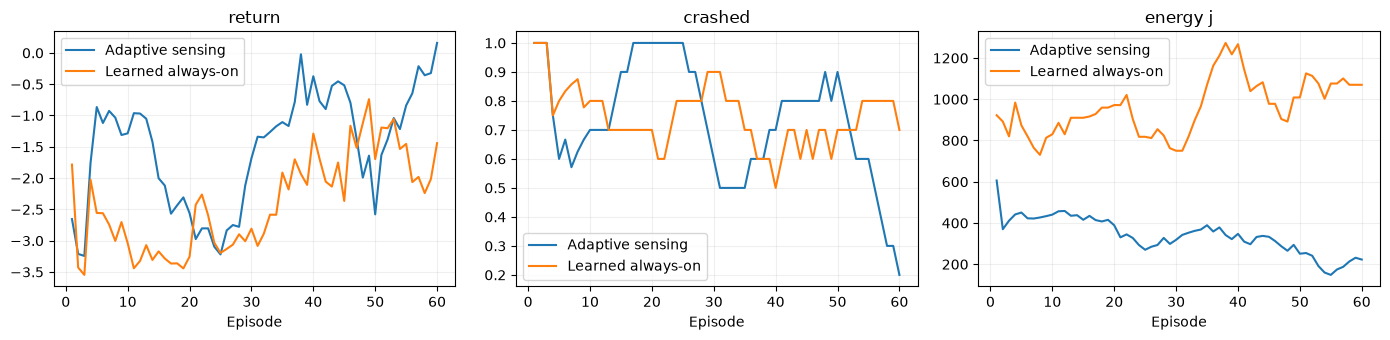

In [4]:
always_on_agent, always_on_history = train_agent(
    config, settings, seed=TRAIN_SEED, modes=("all_on",))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for label, history in [("Adaptive sensing", adaptive_history), ("Learned always-on", always_on_history)]:
    for ax, metric in zip(axes, ["return", "crashed", "energy_j"]):
        rolling = history[metric].astype(float).rolling(min(10, TRAIN_EPISODES), min_periods=1).mean()
        ax.plot(history.episode, rolling, label=label)
        ax.set(xlabel="Episode", title=metric.replace("_", " "))
        ax.grid(alpha=.2)
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

## 5. Evaluate without exploration or learning

All four policies start from the same held-out traffic seeds for each condition:
learned adaptive sensing, learned always-on sensing, fixed IDLE/all-on, and random
driving/all-on. Evaluation uses epsilon=0, breaks value ties with a seeded RNG,
and does not change agent weights.

Report crashes, completion, distance, and sensing power together. **Lower total
energy can simply mean an earlier crash.** Mean power corrects for episode length
but does not establish safety. Total reward also depends on our chosen energy and
confidence penalties. The model can be confidently wrong.

Four seeds per weather condition are an exploratory check. They do not establish
statistical significance. Later use separate validation/test sets and multiple
independent training seeds.

**Interpretation:** lower crash rates can come from slower driving rather than
better sensing. A policy that spends most of its time with sensors off may have
learned a conservative speed pattern. Check sensing-mode use, speed, and actions;
these comparisons do not establish that sensor information caused an improvement.

In [5]:
agents = {"adaptive": adaptive_agent, "learned_all_on": always_on_agent,
          "idle_all_on": None, "random_all_on": None}
frozen_weights = adaptive_agent.weights.copy()
evaluation = evaluate_agents(config, agents, TEST_SEEDS, TEST_WEATHER)
assert np.array_equal(frozen_weights, adaptive_agent.weights)
summary = evaluation.groupby("policy", sort=False).agg(
    episodes=("seed", "count"), mean_return=("return", "mean"),
    return_std=("return", "std"), crash_fraction=("crashed", "mean"),
    completion_fraction=("completed", "mean"), mean_distance_m=("distance_m", "mean"),
    mean_power_w=("mean_power_w", "mean"), mean_energy_j=("energy_j", "mean"),
    mean_uncertainty=("mean_uncertainty", "mean"))
display(summary.round(3))
display(evaluation.groupby(["weather", "policy"], sort=False)[
    ["return", "crashed", "distance_m", "mean_power_w", "mean_uncertainty"]].mean().round(3))

Evaluated clear


Evaluated rain


Evaluated fog


,episodes,mean_return,return_std,crash_fraction,completion_fraction,mean_distance_m,mean_power_w,mean_energy_j,mean_uncertainty
policy,,,,,,,,,
adaptive,12,0.412,0.409,0.00,1.00,263.021,14.942,179.304,0.983
learned_all_on,12,-1.080,3.381,0.50,0.50,211.467,123.000,1045.500,0.964
idle_all_on,12,-2.036,2.547,0.75,0.25,246.183,123.000,1214.625,0.963
random_all_on,12,-2.321,2.002,0.50,0.50,178.287,123.000,953.250,0.967


return  crashed  distance_m  mean_power_w  \
weather policy                                                      
clear   adaptive         0.194     0.00     260.440        15.947   
        learned_all_on  -1.076     0.50     211.467       123.000   
        idle_all_on     -2.031     0.75     246.183       123.000   
        random_all_on   -2.319     0.50     178.287       123.000   
rain    adaptive         0.347     0.00     262.352        16.118   
        learned_all_on  -1.080     0.50     211.467       123.000   
        idle_all_on     -2.039     0.75     246.183       123.000   
        random_all_on   -2.323     0.50     178.287       123.000   
fog     adaptive         0.695     0.00     266.272        12.761   
        learned_all_on  -1.083     0.50     211.467       123.000   
        idle_all_on     -2.040     0.75     246.183       123.000   
        random_all_on   -2.321     0.50     178.287       123.000   

                        mean_uncertainty  
weather policy                            
clear   adaptive                   0.985  
        learned_all_on             0.957  
        idle_all_on                0.956  
        random_all_on              0.965  
rain    adaptive                   0.982  
        learned_all_on             0.964  
        idle_all_on                0.965  
        random_all_on              0.970  
fog     adaptive                   0.983  
        learned_all_on             0.971  
        idle_all_on                0.966  
        random_all_on              0.966

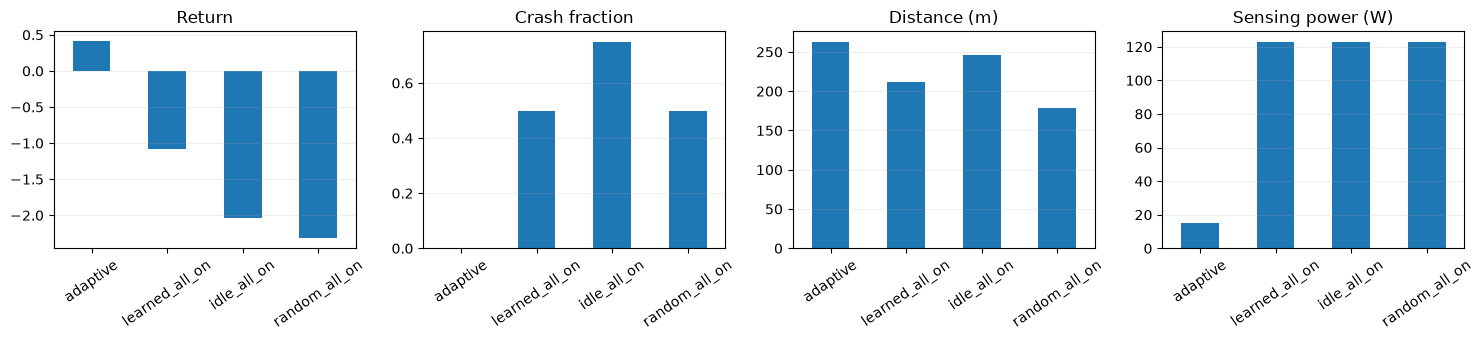

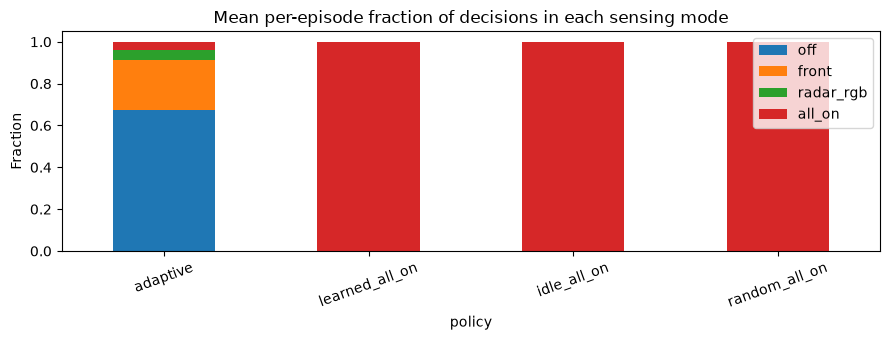

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, metric, title in zip(axes,
        ["mean_return", "crash_fraction", "mean_distance_m", "mean_power_w"],
        ["Return", "Crash fraction", "Distance (m)", "Sensing power (W)"]):
    summary[metric].plot.bar(ax=ax, rot=35, title=title)
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()
fractions = evaluation.groupby("policy", sort=False)[
    ["mode_fraction_off", "mode_fraction_front", "mode_fraction_radar_rgb", "mode_fraction_all_on"]].mean()
fractions.columns = [c.removeprefix("mode_fraction_") for c in fractions.columns]
fractions.plot.bar(stacked=True, figsize=(9, 3.5), rot=20,
                   title="Mean per-episode fraction of decisions in each sensing mode")
plt.ylabel("Fraction")
plt.tight_layout()
plt.show()

## 6. Inspect what the adaptive agent actually does

Watch one held-out scenario. The animation is illustrative; aggregate evaluation
above is the comparison. An initial blind action is expected: reset starts with no
measurements, and choosing sensing now affects only future observations.

Frequent switching can prevent sensors finishing warm-up or cancel pending
measurements. The environment charges active power while warming up. This short
agent has no explicit switching penalty or minimum dwell-time constraint.

seed                           100000
return                       1.409348
driving_return               2.711334
energy_j                       114.75
mean_power_w                   9.5625
mean_uncertainty             0.989364
crashed                         False
completed                        True
distance_m                 274.699729
elapsed_s                        12.0
mean_speed_m_s              22.891644
steps                              24
mode_fraction_off               0.625
mode_fraction_front             0.375
mode_fraction_radar_rgb           0.0
mode_fraction_all_on              0.0
Name: Watched episode, dtype: object

,step,time_s,drive,sensing,reward,energy_j,uncertainty,crashed
0,1,0.5,FASTER,front,0.252631,11.25,0.996154,False
1,2,1.0,SLOWER,off,0.198257,0.90,0.998120,False
2,3,1.5,SLOWER,off,0.056635,0.90,0.999001,False
3,4,2.0,FASTER,front,0.214062,11.25,0.969025,False
4,5,2.5,SLOWER,off,0.067875,0.90,0.987395,False
5,6,3.0,FASTER,front,0.219387,11.25,0.954524,False
6,7,3.5,SLOWER,off,0.070055,0.90,0.983487,False
7,8,4.0,SLOWER,off,0.001252,0.90,0.993813,False
8,9,4.5,FASTER,front,0.076307,11.25,0.970101,False
9,10,5.0,SLOWER,off,0.008479,0.90,0.986787,False


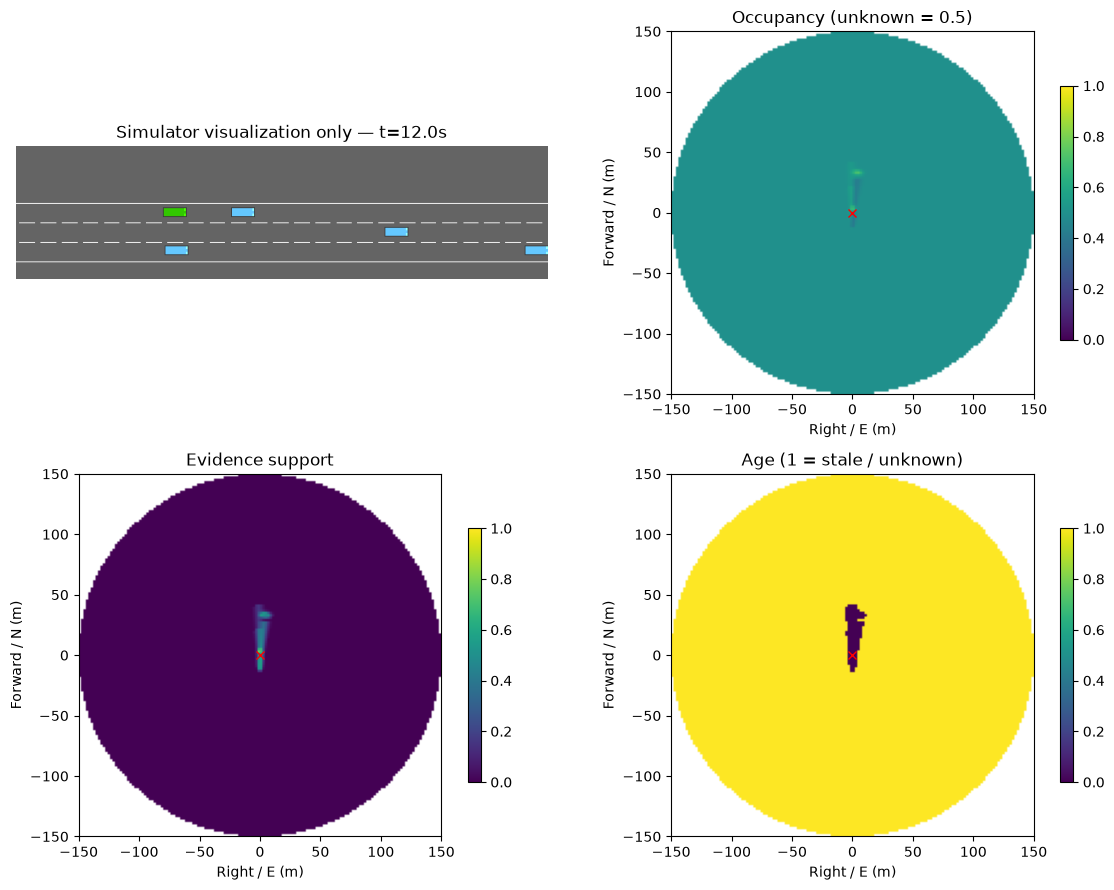

In [7]:
WATCH_SEED = TEST_SEEDS[0]
WATCH_WEATHER = "fog"
watch_config = copy.deepcopy(config)
watch_config.weather.preset = WATCH_WEATHER
watch_metrics, watch = run_agent(watch_config, adaptive_agent, seed=WATCH_SEED, capture=True)
display(pd.Series(watch_metrics, name="Watched episode"))
display(watch.history)
fig = plot_snapshot(watch)
plt.show()

In [8]:
radius = watch.radius_m
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
road_image = axes[0].imshow(watch.frames[0])
axes[0].axis("off")
map_image = axes[1].imshow(np.ma.masked_where(watch.snapshots[0]["valid_cells"] == 0,
    watch.snapshots[0]["grid"][0]), extent=(-radius, radius, -radius, radius), vmin=0, vmax=1)
axes[1].plot(0, 0, "rx")
axes[1].set(xlabel="Right / E (m)", ylabel="Forward / N (m)")
fig.colorbar(map_image, ax=axes[1], shrink=.8)

def update_frame(i):
    road_image.set_data(watch.frames[i])
    obs = watch.snapshots[i]
    map_image.set_data(np.ma.masked_where(obs["valid_cells"] == 0, obs["grid"][0]))
    if i == 0:
        label = "Reset: sensors off, unknown map"
    else:
        row = watch.history.iloc[i - 1]
        label = f"t={row.time_s:.1f}s | {row.drive} | {row.sensing}"
    axes[0].set_title("Simulator visualization only")
    axes[1].set_title(label)
    return road_image, map_image

animation = FuncAnimation(fig, update_frame, frames=len(watch.frames),
                          interval=1000 / config.highway["policy_frequency"], blit=False)
plt.close(fig)
display(HTML(animation.to_jshtml()))

## 7. Read the learned action values

These are estimated discounted returns, not safety probabilities. Below we rank
joint actions for the observation after the first decision (or the final available
observation). High values can be wrong with short training or an inadequate
feature representation. This inspection does not update the model.

In [9]:
encoder = ObservationEncoder(config)
INSPECT_INDEX = min(1, len(watch.snapshots) - 1)
values = adaptive_agent.values(encoder(watch.snapshots[INSPECT_INDEX]))
action_values = pd.DataFrame([
    {"drive": drive, "sensing": mode, "estimated_Q": value}
    for (drive, mode), value in zip(adaptive_agent.actions, values)])
display(action_values.sort_values("estimated_Q", ascending=False).reset_index(drop=True).round(3))

,drive,sensing,estimated_Q
0,SLOWER,off,-0.100
1,LANE_LEFT,off,-0.120
2,FASTER,all_on,-0.133
3,IDLE,all_on,-0.171
4,LANE_RIGHT,radar_rgb,-0.172
5,SLOWER,all_on,-0.179
6,IDLE,radar_rgb,-0.220
7,LANE_RIGHT,off,-0.236
8,LANE_RIGHT,front,-0.240
9,LANE_LEFT,all_on,-0.266


## 8. Save this run

This saves both learned models, configuration, learning settings, training curves,
and held-out measurements together. Loading weights requires the same feature
schema, environment configuration, and action menu. A new timestamped directory
is created each time; saved runs are kept under `runs/`.

In [10]:
SAVE_RUN = True
if SAVE_RUN:
    from datetime import datetime
    from zoneinfo import ZoneInfo
    stamp = datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%d_%H%M%S_%f")
    output = PROJECT_ROOT / "runs/training" / f"agent_{stamp}"
    output.mkdir(parents=True, exist_ok=False)
    config.save(output / "config.json")
    adaptive_agent.save(output / "adaptive_agent.npz")
    always_on_agent.save(output / "always_on_agent.npz")
    adaptive_history.to_csv(output / "adaptive_training.csv", index=False)
    always_on_history.to_csv(output / "always_on_training.csv", index=False)
    evaluation.to_csv(output / "evaluation.csv", index=False)
    summary.to_csv(output / "summary.csv")
    watch.history.to_csv(output / "watched_episode.csv", index=False)
    (output / "metadata.json").write_text(json.dumps({
        "algorithm": "linear Expected SARSA", "feature_schema": FEATURE_SCHEMA,
        "settings": asdict(settings), "training_seed": TRAIN_SEED,
        "test_seeds": TEST_SEEDS, "test_weather": TEST_WEATHER,
        "watch_seed": WATCH_SEED, "watch_weather": WATCH_WEATHER,
        "adaptive_actions": adaptive_agent.actions, "always_on_actions": always_on_agent.actions,
        "package_versions": PACKAGE_VERSIONS, "python": sys.version,
    }, indent=2))
    restored = LinearExpectedSarsa.load(output / "adaptive_agent.npz")
    assert np.array_equal(restored.weights, adaptive_agent.weights)
    print("Saved experiment:", output)
else:
    print("Saving disabled")

Saved experiment: runs/training/agent_20261031_140749_600484


## What to try next

First inspect whether the agent crashes less, completes more episodes, and travels
farther than IDLE. Then compare sensing power between learned policies. A higher
return alone is not enough.

- Train longer using a fresh run; do not assume more episodes fix missing features.
- Repeat training with at least three independent seeds.
- Compare uncertainty penalty enabled versus disabled on validation scenarios.
- Inspect a mode-collapse policy (always off, always on, or constant braking).
  If it scores well while driving poorly, examine the reward and observation.
- Add sensor dwell times or memory only after documenting the current failure.

The first agent is intentionally simple. A richer value model or recurrent policy
may be needed for partial observability, uncertainty, and delayed sensing. Keep
this linear agent as a reproducible baseline when extending the project.